Note: you may need to restart the kernel to use updated packages.
Original Counts:
{'110': 43, '000': 361, '001': 44, '111': 379, '010': 48, '100': 47, '011': 37, '101': 41}

Mitigated Counts:
{'000': 473, '001': 0, '010': 8, '011': 0, '100': 13, '101': 0, '110': 0, '111': 505}

Quantum Circuit:
     ┌───┐             ┌─┐   
q_0: ┤ H ├──■────■─────┤M├───
     └───┘┌─┴─┐  │  ┌─┐└╥┘   
q_1: ─────┤ X ├──┼──┤M├─╫────
          └───┘┌─┴─┐└╥┘ ║ ┌─┐
q_2: ──────────┤ X ├─╫──╫─┤M├
               └───┘ ║  ║ └╥┘
c: 3/════════════════╩══╩══╩═
                     1  0  2 


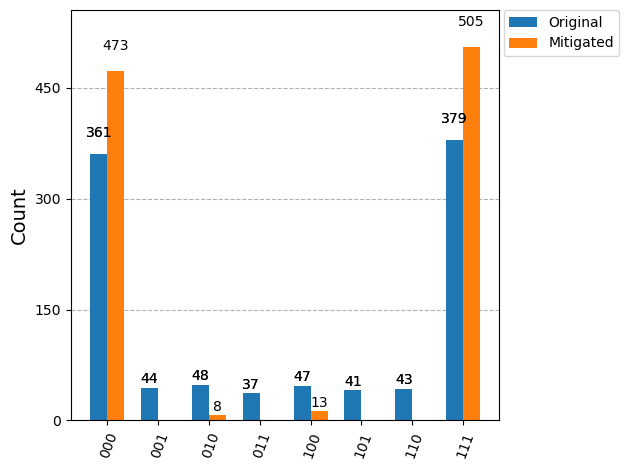

In [2]:

# Install compatible NumPy version
%pip install "numpy==1.26.4" qiskit qiskit-aer matplotlib

# Import libraries
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, ReadoutError
from qiskit.visualization import plot_histogram

# Step 1: Create noise model
noise_model = NoiseModel()

error = ReadoutError([
    [0.9, 0.1],
    [0.1, 0.9]
])

noise_model.add_all_qubit_readout_error(error)

# Step 2: Create quantum circuit
qc = QuantumCircuit(3, 3)

# Apply Hadamard and CNOT gates
qc.h(0)
qc.cx(0, 1)
qc.cx(0, 2)

# Measure qubits
qc.measure([0, 1, 2], [0, 1, 2])

# Step 3: Run noisy circuit
backend = AerSimulator(noise_model=noise_model)

compiled = transpile(qc, backend)

result = backend.run(compiled, shots=1000).result()

counts = result.get_counts()

# Step 4: Measurement calibration
cal_circuits = []

for i in range(8):
    cal = QuantumCircuit(3, 3)

    for q in range(3):
        if (i >> q) & 1:
            cal.x(q)

    cal.measure(range(3), range(3))
    cal_circuits.append(cal)

cal_compiled = transpile(cal_circuits, backend)

cal_result = backend.run(
    cal_compiled, shots=1000
).result()

# Step 5: Create calibration matrix
cal_matrix = np.zeros((8, 8))

for i in range(8):
    cal_counts = cal_result.get_counts(i)

    for state, count in cal_counts.items():
        cal_matrix[int(state, 2), i] = count / 1000

# Step 6: Perform error mitigation
observed = np.zeros(8)

for state, count in counts.items():
    observed[int(state, 2)] = count / 1000

mitigated = np.linalg.pinv(cal_matrix) @ observed

mitigated = np.clip(mitigated, 0, None)
mitigated = mitigated / mitigated.sum()

mitigated_counts = {
    format(i, '03b'): round(mitigated[i] * 1000)
    for i in range(8)
}

# Step 7: Display results
print("Original Counts:")
print(counts)

print("\nMitigated Counts:")
print(mitigated_counts)

# Step 8: Display quantum circuit
print("\nQuantum Circuit:")
print(qc.draw())

# Step 9: Plot histogram
plot_histogram(
    [counts, mitigated_counts],
    legend=['Original', 'Mitigated']
)



# QAI Practical 2 – Tackle Noise with Error Correction
## Oral / Viva Questions and Answers

### Part A: Basic Concepts

### Q1. What is Quantum Error Correction?
Quantum Error Correction (QEC) is a technique used to detect and correct errors in quantum information caused by noise.

### Q2. What is quantum noise?
Quantum noise is unwanted disturbance that affects qubits and causes errors in quantum computations.

### Q3. Why is error correction required in quantum computing?
It improves the reliability of quantum computers by reducing errors caused by noise.

### Q4. What are the main sources of quantum errors?
1. Faulty quantum gates.
2. Faulty measurements.
3. Environmental interactions.
4. Errors during qubit preparation.

### Q5. What is a logical qubit?
A logical qubit is a qubit encoded using multiple physical qubits to protect quantum information.

### Q6. What is a physical qubit?
A physical qubit is an actual hardware or simulated qubit used to store quantum information.

### Q7. What is superposition?
Superposition is a quantum property in which a qubit can exist in a combination of states 0 and 1.

### Q8. What is entanglement?
Entanglement is a quantum phenomenon in which two or more qubits become correlated with each other.

### Q9. What is a Hadamard gate?
A Hadamard gate creates an equal superposition when applied to a qubit in state |0⟩ or |1⟩.

### Q10. What is a CNOT gate?
CNOT stands for Controlled NOT. It flips the target qubit when the control qubit is 1.

### Q11. What is measurement error?
Measurement error occurs when a quantum measurement gives an incorrect classical result.

### Q12. What is error mitigation?
Error mitigation is a technique used to reduce the effect of errors in quantum computation without necessarily correcting the quantum state itself.

### Q13. What is the difference between error correction and error mitigation?
- Error correction detects and corrects errors using redundant quantum information.
- Error mitigation reduces the effect of errors using techniques such as calibration and statistical processing.

### Q14. What is a measurement calibration?
Measurement calibration is the process of measuring known input states to understand the errors introduced during measurement.

### Q15. What is a calibration matrix?
A calibration matrix represents the probabilities of measuring different output states for known input states.

---

## Part B: Code-Based Viva Questions

### Q16. Which programming language is used in this practical?
Python is used to implement the quantum circuit and error mitigation.

### Q17. Which library is used for quantum computing?
Qiskit is used for creating and executing quantum circuits.

### Q18. What is AerSimulator?
AerSimulator is a Qiskit simulator used to execute quantum circuits on a classical computer.

### Q19. What is NoiseModel?
NoiseModel is a Qiskit Aer class used to define noise that affects quantum circuit operations.

### Q20. What is ReadoutError?
ReadoutError represents errors that can occur while measuring qubits.

### Q21. What does QuantumCircuit(3, 3) mean?
It creates a quantum circuit with 3 qubits and 3 classical bits.

### Q22. What does qc.h(0) do?
It applies a Hadamard gate to the first qubit.

### Q23. What does qc.cx(0, 1) do?
It applies a CNOT gate with qubit 0 as the control and qubit 1 as the target.

### Q24. Why do we use qc.cx(0, 2)?
It creates an entanglement correlation between qubit 0 and qubit 2.

### Q25. What does qc.measure() do?
It measures qubits and stores the results in classical bits.

### Q26. What is transpile()?
It converts a quantum circuit into a format suitable for execution on the selected backend.

### Q27. What are shots?
Shots represent the number of times a quantum circuit is executed.

### Q28. Why do we use shots=1000?
To execute the circuit 1000 times and collect measurement statistics.

### Q29. What does get_counts() return?
It returns a dictionary containing measurement outcomes and their occurrence counts.

### Q30. Why do we create 8 calibration circuits?
A 3-qubit system has 2³ = 8 possible computational basis states. We prepare each state for measurement calibration.

---

## Part C: Error Mitigation Questions

### Q31. Why do we introduce readout noise in this program?
To simulate measurement errors and demonstrate how calibration-based mitigation can reduce their effect.

### Q32. What is the purpose of the calibration circuits?
They measure the output probabilities for known input states to construct a calibration matrix.

### Q33. What is a pseudoinverse?
A pseudoinverse is a generalized matrix inverse used to estimate a solution when a normal inverse may not exist.

### Q34. Why do we use np.linalg.pinv()?
It calculates the pseudoinverse of the calibration matrix to estimate corrected probabilities.

### Q35. Why do we use np.clip()?
It removes negative estimated probabilities by replacing them with zero.

### Q36. Why do we normalize the mitigated probabilities?
To ensure that all estimated probabilities add up to 1.

### Q37. What does mitigated_counts represent?
It represents the estimated measurement counts after applying measurement error mitigation.

### Q38. Why do we use Matplotlib?
Matplotlib is used to plot and compare the original and mitigated measurement results.

### Q39. What is the purpose of plt.legend()?
It displays labels that identify the original and mitigated results in the graph.

### Q40. What is the final outcome of this practical?
The practical demonstrates a noisy quantum circuit, performs measurement calibration and error mitigation, and compares the original and mitigated results using a histogram.

---

## Important Oral Questions from Lab Manual

### Q41. How can we adapt error correction codes to different types of noise?
We can select or design error correction codes according to the type of noise affecting the quantum system.

### Q42. How can we design error correction codes that are scalable?
By reducing resource overhead and improving the efficiency of encoding, decoding, and error correction.

### Q43. How can we implement error correction while minimizing overhead?
By using efficient quantum error correction codes and reducing the number of additional physical qubits and operations.

### Q44. How can error correction be combined with quantum feedback control?
Quantum feedback control can monitor errors and apply corrective operations to improve quantum device performance.

---

## Conclusion

Thus, we demonstrated how to tackle noise in quantum computing using measurement calibration and error mitigation. We created a 3-qubit quantum circuit, introduced readout noise, constructed a calibration matrix, estimated mitigated probabilities, and compared the original and mitigated results.
